# EEG-Auth on BED: cross-session EEG authentication

In [1]:
# 1. Hardware and disk
!nvidia-smi || echo "No GPU attached (CPU only: fine for LogReg/Riemannian, slower CNN)"
!df -h /content

Wed Nov 25 17:33:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# 2. Get the project code (models, metrics, training helpers) and install what Colab lacks
import os
REPO = '/content/ECG-brain-auth'
if not os.path.exists(REPO):
    !git clone -q https://github.com/rabiaryal/ECG-brain-auth.git {REPO}
    # private repo? store a GitHub token in Colab Secrets as GITHUB_TOKEN and use:
    # from google.colab import userdata
    # !git clone -q https://{userdata.get('GITHUB_TOKEN')}@github.com/rabiaryal/ECG-brain-auth.git {REPO}
!pip install -q mne pyriemann mat73 pyyaml
import sys
sys.path.insert(0, f'{REPO}/src')
print('repo ready:', os.listdir(f'{REPO}/src/eegauth'))

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.2 which is incompatible.
repo ready: ['models.py', 'features.py', 'api', 'train.py', 'config.py', 'data.py', 'defenses.py', 'metrics.py', '__init__.py', 'attacks.py']


In [3]:
# 3. Connect Google Drive (a pop-up asks you to authorise access)
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# 4. Configuration (edit here only)
N_SUBJECTS   = 21          # BED has 21 subjects
N_SEEDS      = 5           # seeds for the CNN (LogReg / Riemannian are deterministic)
TARGET_FS    = 160.0       # resample 256 Hz -> 160 Hz
BAND         = (1.0, 40.0) # band-pass, Hz
CLIP_S       = 2.0         # clip length, seconds
MAX_SECONDS  = None        # optional cap per resting segment (seconds); None = use all
TRAIN_FRAC   = 0.7         # first 70% (by time) of every session-1 segment = training
VAL_FRAC     = 0.25        # last 25% (by time) of the training part = tuning validation
MAX_EPOCHS   = 60          # CNN max epochs (early stopping on a split of the training clips)
MODELS       = ['logreg', 'riemann', 'cnn']
# Which events are resting state? Regexes on the lower-cased event label. Check them against the
# labels printed by cell 8 and edit if they don't match.
REST_RULES   = {'eyes_closed': r'clos', 'eyes_open': r'open'}
LABEL_FIELD  = None        # name of the ADDITIONAL_INFO field holding the stimulus name; None = auto
# Google Drive locations (MyDrive = your Drive root)
DRIVE_BED_DIR = '/content/drive/MyDrive/BED/BED3'            # <-- folder in YOUR Drive that holds the BED files; edit this
WORK          = '/content/drive/MyDrive/eeg_auth_bed'   # processed data + results are saved here (Drive, resumable)
print('Drive BED folder:', DRIVE_BED_DIR)
print('Work/results folder:', WORK)

Drive BED folder: /content/drive/MyDrive/BED/BED3
Work/results folder: /content/drive/MyDrive/eeg_auth_bed


In [5]:
%%writefile /content/ECG-brain-auth/src/eegauth/bed.py
"""BED (Biometric EEG Dataset) support for EEG-Auth: parsing, rest clips, protocols.

BED: Arnau-Gonzalez, Katsigiannis, Arevalillo-Herraez, Ramzan, IEEE Internet of
Things Journal 8(15), 2021 (Zenodo 4309471). RESTRICTED data: keep it out of git.

Documented format of RAW_PARSED/sN_sM.mat:
    recording : (time @ 256 Hz, 17) COUNTER INTERPOLATED F3 FC5 AF3 F7 T7 P7 O1 O2 P8 T8 F8 AF4 FC6 F4 UNIX_TIMESTAMP
    events    : cell (n, 3) = START_UNIX, END_UNIX, ADDITIONAL_INFO (struct)
The stimulus labels inside ADDITIONAL_INFO are not documented: they are
discovered at run time and matched with configurable regex rules.

Protocol: train = first `train_frac` (by time) of every session-1 segment;
same-session test = the later part of those segments (after a gap);
1-week test = session 2; 2-week test = session 3. One training set for all
three columns keeps them comparable.
"""
from __future__ import annotations

import json
import re
import time
from math import gcd
from pathlib import Path
from typing import Any, Callable, Dict, List, Sequence, Tuple

import numpy as np

EMOTIV_COLUMNS = ["COUNTER", "INTERPOLATED", "F3", "FC5", "AF3", "F7", "T7", "P7", "O1",
                  "O2", "P8", "T8", "F8", "AF4", "FC6", "F4", "UNIX_TIMESTAMP"]
BED_CHANNELS = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1", "O2", "P8", "T8",
                "FC6", "F4", "F8", "AF4"]
SOURCE_FS = 256
TASKS = ["eyes_closed", "eyes_open"]
DEFAULT_RULES = {"eyes_closed": r"clos", "eyes_open": r"open"}
LABEL_KEYS = ("stimuli", "stimulus", "stim", "type", "name", "label", "task",
              "condition", "event", "class")


# ------------------------------ reading ------------------------------------ #
def load_bed_mat(path):
    from scipy.io import loadmat

    try:
        m = loadmat(str(path), squeeze_me=True, struct_as_record=False)
    except NotImplementedError:  # MATLAB v7.3 (HDF5)
        import mat73

        m = mat73.loadmat(str(path))
    if "recording" not in m or "events" not in m:
        raise KeyError(f"{path}: expected 'recording' and 'events', found "
                       f"{[k for k in m if not k.startswith('__')]}")
    return np.asarray(m["recording"], dtype=np.float64), m["events"]


def _plain(x, depth=0):
    if depth > 6:
        return "..."
    if hasattr(x, "_fieldnames"):
        return {k: _plain(getattr(x, k), depth + 1) for k in x._fieldnames}
    if isinstance(x, dict):
        return {str(k): _plain(v, depth + 1) for k, v in x.items()}
    if isinstance(x, bytes):
        return x.decode("utf-8", "replace")
    if isinstance(x, np.ndarray):
        if x.dtype == object:
            return [_plain(i, depth + 1) for i in x.ravel().tolist()[:20]]
        return x.tolist() if x.size <= 10 else f"<array {x.shape} {x.dtype}>"
    if isinstance(x, np.generic):
        return x.item()
    if isinstance(x, (list, tuple)):
        return [_plain(i, depth + 1) for i in list(x)[:20]]
    return x


def parse_events(events) -> List[Dict[str, Any]]:
    if isinstance(events, np.ndarray) and events.ndim == 1 and events.shape[0] == 3:
        rows = [list(events)]
    elif isinstance(events, np.ndarray):
        rows = [list(r) for r in np.atleast_2d(events)]
    else:
        rows = [list(r) for r in events]
    return [{"start": float(np.asarray(r[0]).ravel()[0]), "end": float(np.asarray(r[1]).ravel()[0]),
             "info": _plain(r[2]) if len(r) > 2 else {}} for r in rows]


def event_label(info, label_field=None) -> str:
    if isinstance(info, dict):
        if label_field and label_field in info:
            return str(info[label_field]).lower()
        lower = {k.lower(): v for k, v in info.items()}
        for k in LABEL_KEYS:
            if isinstance(lower.get(k), str):
                return lower[k].lower()
        strs = [v for v in info.values() if isinstance(v, str)]
        if strs:
            return " ".join(strs).lower()
    return str(info).lower()[:200]


def classify_rest(label, rules=None):
    rules = rules or DEFAULT_RULES
    for task in TASKS:  # closed first
        if re.search(rules[task], label):
            return task
    return None


def inspect_mat(path, max_events=5) -> Dict[str, Any]:
    rec, ev = load_bed_mat(path)
    events = parse_events(ev)
    ts = rec[:, -1]
    labels: Dict[str, int] = {}
    for e in events:
        lab = event_label(e["info"])
        labels[lab] = labels.get(lab, 0) + 1
    d = np.median(np.diff(ts)) if rec.shape[0] > 2 else 0
    return {"recording_shape": rec.shape, "assumed_columns": EMOTIV_COLUMNS,
            "assumed_sampling_rate_hz": SOURCE_FS,
            "measured_rate_hz": float(1.0 / d) if d > 0 else None,
            "timestamp_range": (float(ts[0]), float(ts[-1])), "n_events": len(events),
            "first_events": events[:max_events], "label_counts": labels,
            "info_keys": sorted({k for e in events if isinstance(e["info"], dict) for k in e["info"]}),
            "nan_in_recording": int(np.isnan(rec).sum())}


# ---------------------------- preprocessing -------------------------------- #
def cut_clips(data, clip_samples):
    n = data.shape[1] // clip_samples
    if n == 0:
        return np.empty((0, data.shape[0], clip_samples), dtype=np.float32)
    x = data[:, : n * clip_samples].reshape(data.shape[0], n, clip_samples)
    return x.transpose(1, 0, 2).astype(np.float32)


def extract_rest_clips(rec, events_raw, *, rules=None, label_field=None, target_fs=160.0,
                       source_fs=SOURCE_FS, l_freq=1.0, h_freq=40.0, clip_s=2.0,
                       trim_s=1.0, max_seconds=None) -> Dict[str, Any]:
    """Filter whole recording (1-40 Hz), cut rest events, resample, cut 2 s clips."""
    import mne
    from scipy.signal import resample_poly

    cols = [EMOTIV_COLUMNS.index(c) for c in BED_CHANNELS]
    data = rec[:, cols].T
    if not np.isfinite(data).all():
        raise ValueError("recording contains NaN/Inf")
    ts = rec[:, EMOTIV_COLUMNS.index("UNIX_TIMESTAMP")]
    data = mne.filter.filter_data(data, source_fs, l_freq, h_freq, verbose="ERROR")
    up, down = int(target_fs), int(source_fs)
    g = gcd(up, down)
    up, down = up // g, down // g
    clip_samples = int(round(clip_s * target_fs))
    events = parse_events(events_raw)
    scale = 1e-3 if events and events[0]["start"] > 1e11 and ts[-1] < 1e11 else 1.0
    xs, tasks, segs, poss, n_rest = [], [], [], [], 0
    for k, e in enumerate(events):
        task = classify_rest(event_label(e["info"], label_field), rules)
        if task is None:
            continue
        n_rest += 1
        i0 = int(np.searchsorted(ts, e["start"] * scale)) + int(trim_s * source_fs)
        i1 = int(np.searchsorted(ts, e["end"] * scale)) - int(trim_s * source_fs)
        if max_seconds is not None:
            i1 = min(i1, i0 + int(max_seconds * source_fs))
        if i1 - i0 < int(clip_s * source_fs):
            continue
        clips = cut_clips(resample_poly(data[:, i0:i1], up, down, axis=1), clip_samples)
        if len(clips) == 0:
            continue
        xs.append(clips)
        tasks += [TASKS.index(task)] * len(clips)
        segs += [k] * len(clips)
        poss += list(range(len(clips)))
    X = np.concatenate(xs) if xs else np.empty((0, len(BED_CHANNELS), clip_samples), np.float32)
    return {"X": X, "task": np.asarray(tasks, np.int8), "seg": np.asarray(segs, np.int32),
            "pos": np.asarray(poss, np.int32),
            "diag": {"n_events": len(events), "n_rest_events": n_rest, "n_clips": int(len(X))}}


def combine_arrays(parts):
    return {k: np.concatenate([p[k] for p in parts])
            for k in ("X", "subject", "session", "task", "seg", "pos")}


def find_mats(root) -> Dict[Tuple[int, int], Path]:
    """Map (subject, session) -> path for files named sN_sM.mat under root."""
    found = {}
    for p in sorted(Path(root).rglob("*.mat")):
        m = re.fullmatch(r"s(\d+)_s(\d+)\.mat", p.name, flags=re.I)
        if m:
            found.setdefault((int(m.group(1)), int(m.group(2))), p)
    return found


def prepare_dataset(raw_dir, out_dir, *, mats=None, n_subjects=21, rules=None, label_field=None,
                    target_fs=160.0, l_freq=1.0, h_freq=40.0, clip_s=2.0, max_seconds=None,
                    log=print) -> Dict[str, Any]:
    """Per subject (resumable): .mat -> rest clips -> out_dir/processed/sNN.npz; then combine.

    ``mats`` = optional {(subject, session): path}; otherwise files are searched under raw_dir.
    """
    rules = rules or DEFAULT_RULES
    out_dir = Path(out_dir)
    proc = out_dir / "processed"
    proc.mkdir(parents=True, exist_ok=True)
    mats = mats if mats is not None else find_mats(raw_dir)
    skipped, per_rec = [], {}
    for sub in range(1, n_subjects + 1):
        target = proc / f"s{sub:02d}.npz"
        if target.exists():
            log(f"s{sub}: already processed, skipping")
            continue
        parts, t0 = [], time.time()
        for ses in (1, 2, 3):
            path = mats.get((sub, ses))
            if path is None:
                skipped.append({"subject": sub, "session": ses, "reason": "file not found"})
                log(f"s{sub} session {ses}: file not found")
                continue
            try:
                rec, ev = load_bed_mat(path)
                r = extract_rest_clips(rec, ev, rules=rules, label_field=label_field,
                                       target_fs=target_fs, l_freq=l_freq, h_freq=h_freq,
                                       clip_s=clip_s, max_seconds=max_seconds)
            except Exception as exc:  # log and continue
                skipped.append({"subject": sub, "session": ses, "reason": repr(exc)})
                log(f"s{sub} session {ses}: FAILED {exc!r}")
                continue
            if r["diag"]["n_clips"] == 0:
                skipped.append({"subject": sub, "session": ses, "reason": f"no resting clips {r['diag']}"})
                log(f"s{sub} session {ses}: no resting clips {r['diag']}")
                continue
            n = len(r["X"])
            parts.append({"X": r["X"].astype(np.float16), "subject": np.full(n, sub, np.int16),
                          "session": np.full(n, ses, np.int8), "task": r["task"],
                          "seg": r["seg"], "pos": r["pos"]})
            per_rec[f"s{sub}_s{ses}"] = r["diag"]
            log(f"s{sub} session {ses}: {r['diag']}")
        if parts:
            np.savez_compressed(target, **combine_arrays(parts))
            log(f"s{sub} saved ({time.time() - t0:.1f}s)")
    files = sorted(proc.glob("s*.npz"))
    if not files:
        raise RuntimeError("no subject produced resting clips: check REST_RULES / LABEL_FIELD "
                           "against the labels printed by the inspect cell")
    data = combine_arrays([dict(np.load(f)) for f in files])
    np.savez_compressed(out_dir / "bed_subset.npz", **data)
    meta = {"dataset": "BED (Arnau-Gonzalez et al., IEEE IoT J. 2021) - RESTRICTED, do not publish",
            "channels": BED_CHANNELS, "source_fs_hz": SOURCE_FS, "target_fs_hz": target_fs,
            "band_hz": [l_freq, h_freq], "clip_s": clip_s, "dtype": "float16", "tasks": TASKS,
            "rules": rules, "label_field": label_field, "n_clips": int(len(data["X"])),
            "subjects": sorted({int(s) for s in data["subject"]}),
            "clips_per_session": {str(s): int((data["session"] == s).sum()) for s in (1, 2, 3)},
            "clips_per_task": {t: int((data["task"] == i).sum()) for i, t in enumerate(TASKS)},
            "skipped": skipped, "per_recording": per_rec}
    (out_dir / "bed_subset_meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
    return meta


# ------------------------------- splits ------------------------------------ #
def time_block_split(meta, idx, frac, gap=1):
    """Within each (subject, session, task, segment): first `frac` -> head, skip `gap`, rest -> tail."""
    groups: Dict[Tuple[int, int, int, int], List[int]] = {}
    for i in idx:
        key = (int(meta["subject"][i]), int(meta["session"][i]), int(meta["task"][i]), int(meta["seg"][i]))
        groups.setdefault(key, []).append(int(i))
    head, tail = [], []
    for members in groups.values():
        members.sort(key=lambda i: int(meta["pos"][i]))
        n = len(members)
        cut = min(max(int(round(n * frac)), 1), n)
        head += members[:cut]
        tail += members[cut + gap:]
    return np.asarray(sorted(head), dtype=int), np.asarray(sorted(tail), dtype=int)


def build_splits(meta, train_frac=0.7, val_frac=0.25, gap=1):
    sess = meta["session"]
    train, same = time_block_split(meta, np.flatnonzero(sess == 1), train_frac, gap)
    tr_sub, val = time_block_split(meta, train, 1.0 - val_frac, gap)
    return {"train": train, "same_session": same, "tune_train": tr_sub, "tune_val": val,
            "week1": np.flatnonzero(sess == 2), "week2": np.flatnonzero(sess == 3)}


def eligible_subjects(meta, splits):
    sets = [set(meta["subject"][splits[k]].tolist()) for k in ("train", "week1", "week2")]
    return np.asarray(sorted(set.intersection(*sets)), dtype=int)


# ------------------------------- models ------------------------------------ #
class _Base:
    name = ""
    grid: List[Dict[str, Any]] = []
    deterministic = True


class LogRegBandPower(_Base):
    name = "LogReg (band power)"
    grid = [{"C": c} for c in (0.01, 0.1, 1.0, 10.0)]

    def fit(self, X, Xf, y, idx, params, seed, n_classes):
        from eegauth.train import fit_baseline, score_matrix

        pipe = fit_baseline(Xf[idx], y[idx], kind="logreg", C=params["C"], random_state=seed)
        return lambda j: score_matrix(pipe, Xf[j], n_classes)


class RiemannianTangent(_Base):
    name = "Riemannian (tangent space + LogReg)"
    grid = [{"C": c} for c in (0.01, 0.1, 1.0)]

    def fit(self, X, Xf, y, idx, params, seed, n_classes):
        from pyriemann.estimation import Covariances
        from pyriemann.tangentspace import TangentSpace
        from sklearn.linear_model import LogisticRegression
        from sklearn.pipeline import Pipeline
        from sklearn.preprocessing import StandardScaler

        from eegauth.train import PerChannelNormalizer, score_matrix

        norm = PerChannelNormalizer().fit(X[idx])  # train stats only
        pipe = Pipeline([("cov", Covariances(estimator="oas")),
                         ("ts", TangentSpace(metric="riemann")), ("sc", StandardScaler()),
                         ("clf", LogisticRegression(C=params["C"], max_iter=2000, random_state=seed))])
        pipe.fit(norm.transform(X[idx]).astype(np.float64), y[idx])
        return lambda j: score_matrix(pipe, norm.transform(X[j]).astype(np.float64), n_classes)


class EEGNetStyleCNN(_Base):
    """The repo's compact EEGNet-style CNN (EEGCNNSmall), not the original EEGNet."""
    name = "EEGNet-style CNN"
    grid = [{"n_filters": f, "dropout": d} for f in (16, 32) for d in (0.3, 0.5)]
    deterministic = False

    def __init__(self, max_epochs=60, patience=8, lr=1e-3, batch_size=64):
        self.max_epochs, self.patience, self.lr, self.batch_size = max_epochs, patience, lr, batch_size

    def fit(self, X, Xf, y, idx, params, seed, n_classes):
        import torch

        from eegauth.models import EEGCNNSmall, get_device
        from eegauth.train import PerChannelNormalizer, cnn_softmax_scores, train_cnn

        device = get_device()
        torch.manual_seed(seed)
        norm = PerChannelNormalizer().fit(X[idx])
        Xtr = norm.transform(X[idx])
        model = EEGCNNSmall(n_channels=Xtr.shape[1], n_samples=Xtr.shape[2], n_classes=n_classes,
                            n_filters=params["n_filters"], dropout=params["dropout"]).to(device)
        train_cnn(model, Xtr, y[idx], lr=self.lr, batch_size=self.batch_size,
                  max_epochs=self.max_epochs, patience=self.patience, val_fraction=0.1,
                  device=device, seed=seed, verbose=False)
        model.eval()
        return lambda j: cnn_softmax_scores(model, norm.transform(X[j]), device=device)


# ----------------------------- evaluation ---------------------------------- #
def _eval(scores, y):
    from eegauth.metrics import verification_metrics
    from eegauth.train import genuine_impostor_scores

    gen, imp = genuine_impostor_scores(scores, y)
    m = verification_metrics(gen, imp)
    return {"identification_accuracy": float(np.mean(scores.argmax(1) == y)), "eer": m.eer,
            "auc": m.auc, "far_at_eer": m.far_at_eer, "frr_at_eer": m.frr_at_eer, "n_clips": int(len(y))}


def run_protocols(data, models, *, seeds=(0, 1, 2, 3, 4), train_frac=0.7, val_frac=0.25, gap=1,
                  sfreq=160.0, log=print) -> Dict[str, Any]:
    """Tune on a validation split of the training data only, then evaluate 3 protocols."""
    from eegauth.features import log_band_power_features

    meta = {k: data[k] for k in ("subject", "session", "task", "seg", "pos")}
    splits = build_splits(meta, train_frac, val_frac, gap)
    subs = eligible_subjects(meta, splits)
    if len(subs) < 2:
        raise ValueError(f"need >= 2 subjects present in sessions 1, 2 and 3; got {len(subs)}")
    keep = np.isin(meta["subject"], subs)
    remap = {int(s): i for i, s in enumerate(subs)}
    y_all = np.array([remap.get(int(s), -1) for s in meta["subject"]])
    splits = {k: v[keep[v]] for k, v in splits.items()}
    n_classes = len(subs)
    X = data["X"].astype(np.float32)
    Xf = log_band_power_features(X, sfreq=sfreq)
    log(f"subjects used: {n_classes}; clips train={len(splits['train'])}, "
        f"same-session={len(splits['same_session'])}, 1-week={len(splits['week1'])}, "
        f"2-week={len(splits['week2'])}")
    out: Dict[str, Any] = {"n_subjects": n_classes, "subjects": subs.tolist(),
                           "clips": {k: int(len(v)) for k, v in splits.items()},
                           "seeds": list(seeds), "models": {}}
    for model in models:
        best, best_key, tuning = None, (np.inf, 0.0), []
        for params in model.grid:  # tuning: train-only split, first seed
            scorer = model.fit(X, Xf, y_all, splits["tune_train"], params, seeds[0], n_classes)
            r = _eval(scorer(splits["tune_val"]), y_all[splits["tune_val"]])
            tuning.append({"params": params, "val_eer": r["eer"], "val_acc": r["identification_accuracy"]})
            key = (r["eer"], -r["identification_accuracy"])
            if key < best_key:
                best, best_key = params, key
        log(f"[{model.name}] best params {best} (val EER {best_key[0]:.4f})")
        per_seed = []
        for sd in (list(seeds) if not model.deterministic else [seeds[0]]):
            scorer = model.fit(X, Xf, y_all, splits["train"], best, sd, n_classes)
            res = {p: _eval(scorer(splits[p]), y_all[splits[p]]) for p in ("same_session", "week1", "week2")}
            per_seed.append(res)
            log(f"[{model.name}] seed {sd}: " + " | ".join(f"{p} EER {res[p]['eer']:.4f}" for p in res))
        agg: Dict[str, Any] = {}
        for proto in ("same_session", "week1", "week2"):
            for metric in ("eer", "identification_accuracy"):
                v = np.array([s[proto][metric] for s in per_seed])
                agg.setdefault(proto, {})[metric] = {"mean": float(v.mean()), "std": float(v.std()),
                                                     "n_runs": int(len(v))}
        out["models"][model.name] = {"best_params": best, "tuning": tuning,
                                     "deterministic": model.deterministic,
                                     "per_seed": per_seed, "summary": agg}
    return out


def results_table(results, metric="eer") -> str:
    fmt = lambda s: f"{100 * s['mean']:.2f} ± {100 * s['std']:.2f}%"
    lines = ["| Model | Same-session | 1-week | 2-week |", "|---|---|---|---|"]
    for name, r in results["models"].items():
        s = r["summary"]
        lines.append(f"| {name} | " + " | ".join(fmt(s[p][metric]) for p in ("same_session", "week1", "week2")) + " |")
    return "\n".join(lines)


def save_report(results, out_dir) -> str:
    """Write bed_results.json, bed_table.md and bed_eer.png; return the markdown."""
    import matplotlib.pyplot as plt

    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    (out / "bed_results.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
    md = (f"## EER (mean ± std over seeds)\n\n{results_table(results, 'eer')}\n\n"
          f"## Identification accuracy\n\n{results_table(results, 'identification_accuracy')}\n\n"
          f"Subjects: {results['n_subjects']}; clips: {results['clips']}.\n"
          "Deterministic models (LogReg, Riemannian) run once; their std is 0 by construction.\n")
    (out / "bed_table.md").write_text(md, encoding="utf-8")
    protos = [("same_session", "same-session"), ("week1", "1 week"), ("week2", "2 weeks")]
    fig, ax = plt.subplots(figsize=(7, 4))
    k = max(len(results["models"]), 1)
    w = 0.8 / k
    for i, (name, r) in enumerate(results["models"].items()):
        ax.bar(np.arange(3) + i * w, [100 * r["summary"][p]["eer"]["mean"] for p, _ in protos], w,
               yerr=[100 * r["summary"][p]["eer"]["std"] for p, _ in protos], capsize=3, label=name)
    ax.set_xticks(np.arange(3) + w * (k - 1) / 2)
    ax.set_xticklabels([l for _, l in protos])
    ax.set_ylabel("EER (%)")
    ax.set_title(f"BED: EER by time gap to training session ({results['n_subjects']} subjects)")
    ax.legend(fontsize=8)
    fig.savefig(out / "bed_eer.png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    return md

Writing /content/ECG-brain-auth/src/eegauth/bed.py


In [6]:
# 6. Load the BED module written above (cell 5) and check it imports
import importlib
from eegauth import bed
importlib.reload(bed)
print('BED module ready; channels:', bed.BED_CHANNELS)

BED module ready; channels: ['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1', 'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4']


In [7]:
# 7. Find your BED files in Google Drive (read in place; a zip is extracted from a copy on Colab's disk)
import glob, re, shutil, zipfile
from pathlib import Path

LOCAL_RAW = '/content/bed_raw'
os.makedirs(LOCAL_RAW, exist_ok=True)
os.makedirs(WORK, exist_ok=True)
DRIVE_ROOT = '/content/drive/MyDrive'

def has_bed(fns):
    return (any(re.fullmatch(r's\d+_s\d+\.mat', f, re.I) for f in fns) or
            any(f.lower().endswith('.zip') and ('bed' in f.lower() or 'parsed' in f.lower()) for f in fns))

def search_drive(max_depth=6):
    hits = []
    base = DRIVE_ROOT.count('/')
    for dp, dns, fns in os.walk(DRIVE_ROOT):
        dns[:] = [d for d in dns if d not in ('.Trash', '.shortcut-targets-by-id') and os.path.join(dp, d) != WORK]
        if dp.count('/') - base >= max_depth:
            dns[:] = []
        if has_bed(fns):
            hits.append(dp)
    return hits

if os.path.isdir(DRIVE_BED_DIR) and (bed.find_mats(DRIVE_BED_DIR) or glob.glob(f'{DRIVE_BED_DIR}/**/*.zip', recursive=True)):
    roots = [DRIVE_BED_DIR]
else:
    print(f'{DRIVE_BED_DIR} not found or has no BED files; searching your Drive ...')
    roots = search_drive()
    print('found BED files in:', roots)
assert roots, ('No BED files (sN_sM.mat or a zip) found in Drive. Check that the upload finished, then set '
               'DRIVE_BED_DIR in cell 4. Top-level Drive folders: ' + str(sorted(os.listdir(DRIVE_ROOT))[:30]))

if not bed.find_mats(LOCAL_RAW):                      # unpack zips once per session (originals stay in Drive)
    for root in roots:
        for z in glob.glob(f'{root}/**/*.zip', recursive=True):
            tmp = '/content/_bed_tmp.zip'
            shutil.copy(z, tmp)
            try:
                with zipfile.ZipFile(tmp) as zf:
                    members = [m for m in zf.namelist() if m.lower().endswith('.mat')]
                    zf.extractall(LOCAL_RAW, members)
                    print(f'extracted {len(members)} .mat files from {Path(z).name}')
            except zipfile.BadZipFile:
                print('skipping bad zip:', z)
            finally:
                os.remove(tmp)

mats = {}
for r in roots + [LOCAL_RAW]:
    for k, v in bed.find_mats(r).items():
        mats.setdefault(k, v)
print(len(mats), 'recordings found | subjects:', sorted({s for s, _ in mats}), '| sessions:', sorted({m for _, m in mats}))
assert mats, 'No files named s<N>_s<M>.mat found in Drive (or in a zip). Upload the RAW_PARSED files.'

/content/drive/MyDrive/BED/BED3 not found or has no BED files; searching your Drive ...
found BED files in: ['/content/drive/MyDrive/BED/BED 3/RAW_PARSED']
63 recordings found | subjects: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21] | sessions: [1, 2, 3]


In [9]:
# 8. Inspect ONE raw file so we use the real format (shapes, rate, channel columns, event labels)
import pprint
first = next(iter(sorted(mats.items())))[1]
info = bed.inspect_mat(first)
print('file:', first.name)
print('recording shape (time x columns):', info['recording_shape'])
print('documented columns:', info['assumed_columns'])
print('documented rate:', info['assumed_sampling_rate_hz'], 'Hz | measured from timestamps:', info['measured_rate_hz'])
print('timestamp range:', info['timestamp_range'], '| NaNs in recording:', info['nan_in_recording'])
print('events:', info['n_events'], '| keys in ADDITIONAL_INFO:', info['info_keys'])
print('\nfirst events:')
pprint.pprint(info['first_events'], width=120)

# Override REST_RULES locally to match the actual labels discovered in the dataset
LOCAL_REST_RULES = {'eyes_closed': r'rest', 'eyes_open': r'eyes'}

print('\nevent labels (count) and how REST_RULES classify them:')
for lab, n in sorted(info['label_counts'].items(), key=lambda kv: -kv[1]):
    print(f'  {n:4d}  {lab[:80]!r:85} -> {bed.classify_rest(lab, LOCAL_REST_RULES)}')
assert info['recording_shape'][1] == 17, 'unexpected column count: update bed.EMOTIV_COLUMNS from the output above'
assert any(bed.classify_rest(l, LOCAL_REST_RULES) for l in info['label_counts']), (
    'No event matched the resting-state rules. Read the labels above and edit REST_RULES / LABEL_FIELD in cell 4.')

file: s1_s1.mat
recording shape (time x columns): (284845, 17)
documented columns: ['COUNTER', 'INTERPOLATED', 'F3', 'FC5', 'AF3', 'F7', 'T7', 'P7', 'O1', 'O2', 'P8', 'T8', 'F8', 'AF4', 'FC6', 'F4', 'UNIX_TIMESTAMP']
documented rate: 256 Hz | measured from timestamps: 250.00321869225726
timestamp range: (1523703058.01, 1523704249.773) | NaNs in recording: 0
events: 66 | keys in ADDITIONAL_INFO: ['CONTENT', 'EXPECTED_VOTES', 'FREQ', 'INPUT', 'OPEN_CLOSED', 'STIMULI', 'VOTED']

first events:
[{'end': 1523703102.312,
  'info': {'CONTENT': './OASIS/images/Tornado 2.jpg',
           'EXPECTED_VOTES': [0.005602, 0.349364],
           'STIMULI': 'IMAGE',
           'VOTED': [1.0, 3.0]},
  'start': 1523703097.31},
 {'end': 1523703127.098,
  'info': {'CONTENT': './OASIS/images/Lake 12.jpg',
           'EXPECTED_VOTES': [0.821782, 0.350902],
           'STIMULI': 'IMAGE',
           'VOTED': [3.0, 2.5]},
  'start': 1523703122.096},
 {'end': 1523703155.668,
  'info': {'CONTENT': './GAPED/images/N

In [11]:
# 9. Preprocess per subject (resumable; saved to Drive after every subject): 1-40 Hz band-pass -> rest segments -> 160 Hz -> 2 s clips
# Define corrected rules to match the actual event labels found in the dataset ('rest' and 'eyes')
CORRECTED_REST_RULES = {'eyes_closed': r'rest', 'eyes_open': r'eyes'}

meta = bed.prepare_dataset(None, WORK, mats=mats, n_subjects=N_SUBJECTS, rules=CORRECTED_REST_RULES, label_field=LABEL_FIELD,
                           target_fs=TARGET_FS, l_freq=BAND[0], h_freq=BAND[1], clip_s=CLIP_S, max_seconds=MAX_SECONDS)
print('done')

s1 session 1: {'n_events': 66, 'n_rest_events': 10, 'n_clips': 109}
s1 session 2: {'n_events': 66, 'n_rest_events': 10, 'n_clips': 137}
s1 session 3: {'n_events': 66, 'n_rest_events': 10, 'n_clips': 140}
s1 saved (1.6s)
s2 session 1: {'n_events': 66, 'n_rest_events': 10, 'n_clips': 137}
s2 session 2: {'n_events': 66, 'n_rest_events': 10, 'n_clips': 140}
s2 session 3: {'n_events': 66, 'n_rest_events': 10, 'n_clips': 128}
s2 saved (1.9s)
s3 session 1: {'n_events': 66, 'n_rest_events': 10, 'n_clips': 140}
s3 session 2: {'n_events': 66, 'n_rest_events': 10, 'n_clips': 138}
s3 session 3: {'n_events': 66, 'n_rest_events': 10, 'n_clips': 126}
s3 saved (1.2s)
s4 session 1: {'n_events': 66, 'n_rest_events': 10, 'n_clips': 137}
s4 session 2: {'n_events': 66, 'n_rest_events': 10, 'n_clips': 140}
s4 session 3: {'n_events': 66, 'n_rest_events': 10, 'n_clips': 134}
s4 saved (1.0s)
s5 session 1: {'n_events': 66, 'n_rest_events': 10, 'n_clips': 140}
s5 session 2: {'n_events': 66, 'n_rest_events': 10, 

In [12]:
# 10. Dataset summary
size_mb = os.path.getsize(f'{WORK}/bed_subset.npz') / 1e6
print(f'bed_subset.npz: {size_mb:.1f} MB | clips: {meta["n_clips"]} | subjects: {len(meta["subjects"])}')
print('clips per session:', meta['clips_per_session'], '| per task:', meta['clips_per_task'])
print('skipped recordings:', len(meta['skipped']))
for s in meta['skipped'][:20]:
    print('  ', s)

bed_subset.npz: 72.2 MB | clips: 8658 | subjects: 21
clips per session: {'1': 2871, '2': 2916, '3': 2871} | per task: {'eyes_closed': 1495, 'eyes_open': 7163}
skipped recordings: 0


In [13]:
# 11. Train and evaluate: tune on a validation split of the training data only, then 3 test protocols
import numpy as np
with np.load(f'{WORK}/bed_subset.npz') as z:
    data = {k: z[k] for k in z.files}
chosen = []
if 'logreg'  in MODELS: chosen.append(bed.LogRegBandPower())
if 'riemann' in MODELS: chosen.append(bed.RiemannianTangent())
if 'cnn'     in MODELS: chosen.append(bed.EEGNetStyleCNN(max_epochs=MAX_EPOCHS))
results = bed.run_protocols(data, chosen, seeds=list(range(N_SEEDS)), train_frac=TRAIN_FRAC, val_frac=VAL_FRAC)
table_md = bed.save_report(results, f'{WORK}/results')
print('saved to', f'{WORK}/results')

subjects used: 21; clips train=2005, same-session=659, 1-week=2916, 2-week=2871
[LogReg (band power)] best params {'C': 1.0} (val EER 0.0116)
[LogReg (band power)] seed 0: same_session EER 0.0228 | week1 EER 0.3449 | week2 EER 0.3967
[Riemannian (tangent space + LogReg)] best params {'C': 1.0} (val EER 0.0003)
[Riemannian (tangent space + LogReg)] seed 0: same_session EER 0.0121 | week1 EER 0.3858 | week2 EER 0.3856


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/conv.py:380: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1104.)
  return F.conv1d(


[EEGNet-style CNN] best params {'n_filters': 32, 'dropout': 0.3} (val EER 0.0396)
[EEGNet-style CNN] seed 0: same_session EER 0.0910 | week1 EER 0.3395 | week2 EER 0.3309
[EEGNet-style CNN] seed 1: same_session EER 0.0895 | week1 EER 0.3587 | week2 EER 0.3438
[EEGNet-style CNN] seed 2: same_session EER 0.0910 | week1 EER 0.3674 | week2 EER 0.3400
[EEGNet-style CNN] seed 3: same_session EER 0.0653 | week1 EER 0.3377 | week2 EER 0.3393
[EEGNet-style CNN] seed 4: same_session EER 0.0802 | week1 EER 0.3546 | week2 EER 0.3553
saved to /content/drive/MyDrive/eeg_auth_bed/results


## EER (mean ± std over seeds)

| Model | Same-session | 1-week | 2-week |
|---|---|---|---|
| LogReg (band power) | 2.28 ± 0.00% | 34.49 ± 0.00% | 39.67 ± 0.00% |
| Riemannian (tangent space + LogReg) | 1.21 ± 0.00% | 38.58 ± 0.00% | 38.56 ± 0.00% |
| EEGNet-style CNN | 8.34 ± 0.99% | 35.16 ± 1.14% | 34.18 ± 0.79% |

## Identification accuracy

| Model | Same-session | 1-week | 2-week |
|---|---|---|---|
| LogReg (band power) | 94.99 ± 0.00% | 21.64 ± 0.00% | 11.29 ± 0.00% |
| Riemannian (tangent space + LogReg) | 97.12 ± 0.00% | 16.84 ± 0.00% | 15.12 ± 0.00% |
| EEGNet-style CNN | 74.84 ± 2.07% | 26.14 ± 1.62% | 22.01 ± 2.66% |

Subjects: 21; clips: {'train': 2005, 'same_session': 659, 'tune_train': 1592, 'tune_val': 371, 'week1': 2916, 'week2': 2871}.
Deterministic models (LogReg, Riemannian) run once; their std is 0 by construction.


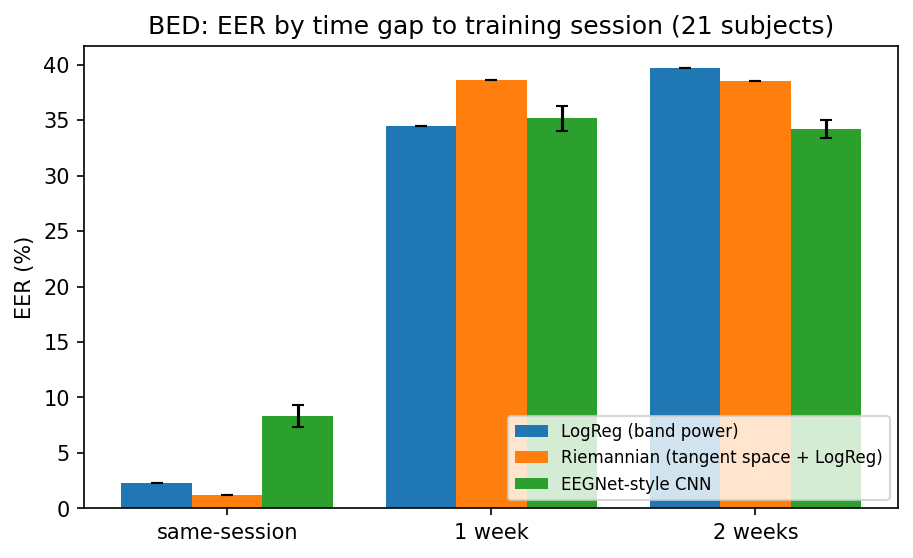

In [14]:
# 12. Results table and figure
from IPython.display import Image, Markdown, display
display(Markdown(open(f'{WORK}/results/bed_table.md').read()))
display(Image(f'{WORK}/results/bed_eer.png'))

In [15]:
# 13. Everything is already saved in your Drive (MyDrive/eeg_auth_bed/results). Optional: also download the results
# (metrics + figure only, no EEG data) as one zip to your computer.
import shutil
from google.colab import files
shutil.make_archive('/content/bed_results', 'zip', f'{WORK}/results')
files.download('/content/bed_results.zip')
# Note: MyDrive/eeg_auth_bed/bed_subset.npz and processed/ are restricted data derived from BED. Keep that folder private.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>